# 08 · Pretraining a small LM end to end

**Pipeline:** raw text → tokenizer → token tensor → model → training loop → curves → perplexity → generation.

Everything here is what a real pretraining run does, minus multi-GPU distribution and a streaming data loader:
- next-token cross-entropy (all positions in parallel thanks to the causal mask)
- AdamW with decay on matrices only, β₂=0.95
- warmup + cosine (or WSD) schedule, gradient clipping, mixed precision on GPU
- validation perplexity, checkpoints, loss/LR/grad-norm curves (your training health dashboard)

**Source:** `llm_edu_suite/training.py`, `llm_edu_suite/model.py`, `llm_edu_suite/data.py`.

## Background: what pre-training is and why it looks the way it does

**Pre-training** turns a randomly initialized transformer into a general model of text by training it on a very large unlabeled corpus. Nobody writes labels: the text supervises itself, because every token is a target for the tokens before it. Everything that comes later in this course (fine-tuning, preference training, RAG, agents) builds on the representations learned here, and almost all of the compute of a modern LLM is spent in this phase.

### The objective: next-token prediction

Any probability distribution over sequences can be factorized with the chain rule:

$$p(x_1, \dots, x_T) = \prod_{t=1}^{T} p(x_t \mid x_{<t})$$

A causal language model learns each factor. Training minimizes the average **cross-entropy** (negative log-likelihood) of the true next token:

$$\mathcal{L}(\theta) = -\frac{1}{T}\sum_{t=1}^{T} \log p_\theta(x_t \mid x_{<t}), \qquad \text{PPL} = e^{\mathcal{L}}$$

**Perplexity** is the exponentiated loss: a perplexity of 20 means the model is, on average, as uncertain as if it were choosing uniformly among 20 tokens. Because loss and perplexity depend on the tokenizer, comparisons between models with different vocabularies usually convert to **bits per byte** (total nats divided by $\ln 2$ and by the number of UTF-8 bytes).

Two properties make this objective efficient:
- **Teacher forcing.** During training the model always conditions on the *true* previous tokens, not on its own predictions, so all positions are independent prediction problems.
- **Causal masking.** With the mask from notebook 03, one forward pass over a sequence of length $T$ produces all $T$ predictions at once. A single sequence gives $T$ training examples for the price of one pass.

### Why the loss has a floor

Let $p$ be the true distribution of text and $q_\theta$ the model. The expected cross-entropy decomposes as

$$H(p, q_\theta) = H(p) + D_{\text{KL}}(p \,\|\, q_\theta) \;\ge\; H(p)$$

The KL term is what training can reduce; the **entropy $H(p)$** of the text itself is the part no model can remove, because the future is genuinely uncertain ("The capital of France is" is predictable; "My favourite colour is" is not). This is the **irreducible loss**, and this notebook's synthetic corpus lets us compute it exactly, which real text never does.

### Alternatives to the causal objective, and why they lost

| objective | example models | what it trains | why it is not the default for LLMs |
|---|---|---|---|
| masked language modeling | BERT (Devlin et al., 2019) | predict ~15 % masked tokens from both sides | only the masked positions give a loss; no natural way to generate text |
| span corruption (encoder-decoder) | T5 (Raffel et al., 2020) | reconstruct masked spans | strong for transfer tasks, but two stacks and a mismatch with free generation |
| mixture of denoisers | UL2 (Tay et al., 2022) | several corruption types | more complex; gains were not decisive at scale |
| **causal LM** | GPT-2, GPT-3, Llama, Qwen, DeepSeek | next token | every token is a target, training equals inference, scales with no special tricks |

GPT-3 (Brown et al., 2020) showed that a large enough causal LM can perform tasks from a few examples in the prompt (**in-context learning**) without any fine-tuning, and that result made the decoder-only causal LM the industry default. Code models add **fill-in-the-middle** training (Bavarian et al., 2022): move a middle span to the end so a causal model learns to infill, at almost no cost to left-to-right ability.

### Data: where most of the quality comes from

The model can only learn what is in the data, so modern reports spend as many pages on data as on architecture. A typical web-scale pipeline:

```
crawl (Common Crawl, code, books, papers, math)
  -> text extraction from HTML
  -> language identification
  -> heuristic filters (length, symbol ratio, repeated lines, ...)
  -> quality classifier (e.g. "is this educational?")
  -> deduplication (exact + MinHash near-duplicates)
  -> PII and toxicity filtering, benchmark decontamination
  -> domain mixing weights, tokenization, shuffling
  -> (late in training) annealing on a smaller high-quality mix
```

Why each step matters:
- **Deduplication** (Lee et al., 2022) reduces memorization of repeated text and improves quality per token; duplicated documents are effectively up-weighted, which wastes compute.
- **Quality filtering** is where open datasets made the biggest recent gains: RefinedWeb (Penedo et al., 2023) showed that well-filtered web data alone can match curated corpora, and FineWeb-Edu (Penedo et al., 2024) used an LLM-annotated classifier to keep educational pages.
- **Repetition**: when unique data runs out, Muennighoff et al. (2023) found that repeating data for a few epochs is almost as good as fresh data, with quickly diminishing returns after that.
- **Decontamination**: if benchmark questions leak into the training set, evaluation numbers become meaningless. It is easy to get wrong.

### Optimizer: AdamW and its hyperparameters

Almost every LLM is trained with **AdamW** (Kingma & Ba, 2015; Loshchilov & Hutter, 2019). For a gradient $g_t$ and parameters $\theta$:

$$m_t = \beta_1 m_{t-1} + (1-\beta_1) g_t, \qquad v_t = \beta_2 v_{t-1} + (1-\beta_2) g_t^2$$
$$\hat m_t = \frac{m_t}{1-\beta_1^t}, \quad \hat v_t = \frac{v_t}{1-\beta_2^t}, \qquad \theta_t = \theta_{t-1} - \eta_t\Big(\frac{\hat m_t}{\sqrt{\hat v_t} + \epsilon} + \lambda\,\theta_{t-1}\Big)$$

- The per-parameter division by $\sqrt{\hat v_t}$ makes the step size roughly independent of the gradient scale, which matters because gradient magnitudes differ by orders of magnitude between embeddings, attention and FFN weights.
- **Decoupled weight decay** ($\lambda\theta$ applied outside the adaptive scaling) is the "W" in AdamW. Plain L2 regularization inside Adam gets divided by $\sqrt{\hat v}$ and so regularizes parameters with large gradients less, which is not what you want.
- Decay is applied to **weight matrices only**, not to norm gains and biases: shrinking a norm gain toward 0 changes the function rather than regularizing it.
- **$\beta_2 = 0.95$** instead of the textbook 0.999 (used since GPT-3): $v_t$ then averages over roughly the last 20 steps instead of 1000, so it reacts quickly when gradient scales change, which reduces loss spikes in large runs.
- **Gradient clipping** (Pascanu et al., 2013) rescales the whole gradient when its norm exceeds a threshold (1.0 is the common choice), a cheap guard against occasional bad batches.

Memory is a real cost: with mixed precision, each parameter needs bf16 weights and gradients plus fp32 master weights and two fp32 Adam moments, about **16 bytes per parameter** (the accounting in the ZeRO paper, Rajbhandari et al., 2020), before activations. A 7B model therefore needs over 100 GB of optimizer-related state, which is why large runs shard it across GPUs (ZeRO / FSDP). Alternatives exist (Adafactor to save memory, Lion, Sophia, and more recently Muon, which some labs now use for large runs), but whether they beat a well-tuned AdamW at scale is still debated.

### Learning-rate schedule

Two pieces, each with a reason:
- **Warmup.** At initialization the Adam second-moment estimates are based on very few steps and the network is far from a well-conditioned region, so full-size updates can blow up. Increasing the LR linearly over the first hundreds to thousands of steps avoids that (Goyal et al., 2017 made warmup standard for large-batch training).
- **Decay.** A high LR makes fast progress but leaves the parameters bouncing around the bottom of the loss valley; lowering it at the end lets them settle. **Cosine decay** (Loshchilov & Hutter, 2017) does this smoothly:

$$\eta_t = \eta_{min} + \tfrac{1}{2}(\eta_{max} - \eta_{min})\Big(1 + \cos\big(\pi\,\tfrac{t - t_{w}}{T - t_{w}}\big)\Big)$$

  Its drawback is that the total length $T$ must be fixed in advance. **Warmup-stable-decay (WSD)** (Hu et al., 2024, MiniCPM; analysed by Hägele et al., 2024) keeps the LR constant and decays only in a short final phase, so you can continue training from any stable-phase checkpoint, or branch several short decays to evaluate different budgets.

### Compute and scaling laws

A useful rule of thumb (Kaplan et al., 2020): training a model with $N$ parameters on $D$ tokens costs

$$C \approx 6\,N\,D \text{ FLOPs}$$

(about 2 FLOPs per parameter per token in the forward pass and 4 in the backward pass, ignoring attention's sequence-length term). Kaplan et al. found that loss falls as a **power law** in $N$, $D$ and $C$ over many orders of magnitude, which is what made it possible to plan large runs from small ones.

Hoffmann et al. (2022, "Chinchilla") fitted a parametric form

$$L(N, D) = E + \frac{A}{N^{\alpha}} + \frac{B}{D^{\beta}}$$

and, minimizing it under a fixed budget $C = 6ND$, found that parameters and data should grow **in equal proportion**, about **20 tokens per parameter**. Their 70B model trained on 1.4T tokens outperformed the 280B Gopher trained with the same compute. Kaplan's earlier advice (grow the model faster than the data) was largely an artifact of methodology, such as not adjusting the learning-rate schedule to the run length. Even the Chinchilla fit has been re-examined (Besiroglu et al., 2024, found problems with one of its three estimation approaches), so treat the exact exponents as approximate.

**Compute-optimal is not deployment-optimal.** Chinchilla minimizes *training* compute. A model served to millions of users is paid for mostly at inference, where cost scales with $N$. So labs now **over-train** small models far beyond 20 tokens per parameter (Sardana & Frankle, 2023, formalize this): Llama 3 8B was trained on over 15T tokens, roughly 1,900 tokens per parameter. The loss keeps improving, only more slowly per FLOP.

The $E$ term is the irreducible loss from above. The other two terms say that a finite model and finite data each add an excess loss that shrinks as a power of their size.

### Stability: what goes wrong in real runs

- **Loss spikes**: sudden jumps, often tied to large attention logits or bad batches. Remedies: QK-norm (Dehghani et al., 2023; Wortsman et al., 2023 studied these instabilities in small proxies), a lower LR, $\beta_2 = 0.95$, z-loss on the output logits, and in the worst case restarting from an earlier checkpoint and skipping the offending batches, which the PaLM team did.
- **Divergence** from too high a peak LR; small-scale LR sweeps (and parametrizations such as $\mu$P, Yang et al., 2022, that transfer the best LR across widths) help find a safe value.
- **Data bugs**: a broken shuffle, a tokenizer mismatch between data and model, or validation text leaking into training. The sanity checks in this notebook (initial loss, causal-mask leak test) catch some of them cheaply.

### Key papers

- Radford et al. (2019), *Language Models are Unsupervised Multitask Learners* (GPT-2).
- Brown et al. (2020), *Language Models are Few-Shot Learners* (GPT-3).
- Kaplan et al. (2020), *Scaling Laws for Neural Language Models*.
- Hoffmann et al. (2022), *Training Compute-Optimal Large Language Models* (Chinchilla).
- Loshchilov & Hutter (2019), *Decoupled Weight Decay Regularization* (AdamW).
- Loshchilov & Hutter (2017), *SGDR: Stochastic Gradient Descent with Warm Restarts* (cosine schedule).
- Hägele et al. (2024), *Scaling Laws and Compute-Optimal Training Beyond Fixed Training Durations* (WSD and cooldowns).
- Lee et al. (2022), *Deduplicating Training Data Makes Language Models Better*.
- Penedo et al. (2024), *The FineWeb Datasets: Decanting the Web for the Finest Text Data at Scale*.
- Muennighoff et al. (2023), *Scaling Data-Constrained Language Models*.
- Sardana & Frankle (2023), *Beyond Chinchilla-Optimal: Accounting for Inference in Language Model Scaling Laws*.
- Llama Team, Meta (2024), *The Llama 3 Herd of Models*.

In [1]:
import os, sys, math, time, tempfile
ROOT = os.path.abspath(".")
while not os.path.isdir(os.path.join(ROOT, "llm_edu_suite")) and os.path.dirname(ROOT) != ROOT:
    ROOT = os.path.dirname(ROOT)                    # notebooks live in notebooks/<topic>/, so climb up to the repo root
sys.path.insert(0, ROOT)                            # so that `import llm_edu_suite` works from the notebook
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from llm_edu_suite.utils import seed_everything, get_device, count_params, human, show_mask
seed_everything(0)
device = get_device()
print("torch", torch.__version__, "| device", device)

torch 2.14.1+cu130 | device cuda


## 1. Text → tokens
We use a generated English-like corpus so the notebook runs offline. To use real text, download e.g. tiny Shakespeare
(`curl -O https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt`) and set `TEXT_PATH`.

**Two details that matter at any scale.** First, the tokenizer is trained on a sample of the text and then frozen; the model never sees raw characters, only token ids, so the *chars per token* ratio printed below tells you how much text each prediction covers. Second, the validation set is a contiguous held-out slice. With real data you would split by *document* after deduplication, otherwise near-copies of training documents end up in validation and the validation loss looks better than it should.

In [2]:
from llm_edu_suite.tokenizer import ByteBPETokenizer
from llm_edu_suite.data import template_text_corpus, load_text_file, train_val_split

TEXT_PATH = None    # e.g. os.path.join(ROOT, "data", "input.txt")
text = load_text_file(TEXT_PATH) if TEXT_PATH else template_text_corpus(n_sentences=20_000, seed=1)
print(f"{len(text):,} characters")

tok = ByteBPETokenizer().train(text[:300_000], vocab_size=1024)
ids = torch.tensor(tok.encode(text), dtype=torch.long)
train_data, val_data = train_val_split(ids, val_frac=0.1)
print(f"{len(ids):,} tokens ({len(text)/len(ids):.2f} chars/token) | train {len(train_data):,} | val {len(val_data):,}")

1,121,799 characters
182,129 tokens (6.16 chars/token) | train 163,916 | val 18,213


## 2. Model and sanity checks
Initial loss must be ≈ ln(V): an untrained model predicts uniformly. Much higher → bad init (logits too large); lower → information leak (broken causal mask).

**Where ln(V) comes from.** With small initial weights the logits are all close to zero, so the softmax is close to uniform, $p(x_t) \approx 1/V$ for every token, and the cross-entropy is $-\log(1/V) = \ln V$. If the output logits start with a large variance, the model is confidently wrong about random tokens and the initial loss lands well above $\ln V$; that wastes the first part of training undoing the initialization. The second check works for a different reason: under a correct causal mask, position $t$ can only see positions $\le t$, so changing the *last* token must leave the logits of every earlier position unchanged. A model that "cheats" by looking ahead would show a training loss that is too good to be true and would fail completely at generation time.

In [3]:
from llm_edu_suite.model import ModelConfig, TransformerLM
from llm_edu_suite.data import get_batch

cfg = ModelConfig(vocab_size=tok.vocab_size, max_seq_len=256, d_model=192, n_layers=4, n_heads=6, n_kv_heads=2)
model = TransformerLM(cfg).to(device)
x, y = get_batch(train_data, 128, 8, device)
with torch.no_grad():
    _, loss0 = model(x, y)
print(f"params {human(model.num_params())} | initial loss {loss0.item():.3f} vs ln(V) = {math.log(cfg.vocab_size):.3f}")

# Causal-mask leak test: changing a future token must not change the logits at earlier positions.
x2 = x.clone(); x2[:, -1] = (x2[:, -1] + 1) % cfg.vocab_size
with torch.no_grad():
    l1, _ = model(x); l2, _ = model(x2)
print("no future leak:", torch.allclose(l1[:, :-1], l2[:, :-1], atol=1e-5))

params 1.67M | initial loss 6.295 vs ln(V) = 6.240
no future leak: True


## 3. Train
`TrainConfig` collects the knobs. On CPU this takes a few minutes; shrink `steps` or the model if needed.

**One training step, in order.** Sample a batch of `batch_size` windows of `block_size + 1` tokens; inputs are the first `block_size`, targets are the same windows shifted by one. Run the forward pass (in bf16 autocast on GPU), compute the mean cross-entropy over all `batch_size × block_size` positions, backpropagate, clip the global gradient norm to `grad_clip`, set the learning rate from the schedule, and take one AdamW step. The knobs map directly onto the Background section: `max_lr` and `warmup` are $\eta_{max}$ and $t_w$, `weight_decay` is $\lambda$, `schedule` picks cosine or WSD.

**Tokens per step** is `batch_size × block_size` = 4,096 here. Real runs use millions of tokens per step (often through gradient accumulation across many GPUs), because a larger batch gives a less noisy gradient. Past a "critical batch size" the extra tokens stop buying faster progress per step, which is why some large runs (GPT-3 and Llama 3, for example) ramp the batch size up during training instead of fixing it at the start.

step     0 | train 6.277 | val 6.180 | ppl   483.2 | lr 5.00e-05 | grad 3.90 |   0.3s


step   100 | train 1.033 | val 1.037 | ppl     2.8 | lr 2.96e-03 | grad 0.34 |   2.4s


step   200 | train 1.014 | val 1.038 | ppl     2.8 | lr 2.58e-03 | grad 0.35 |   4.5s


step   300 | train 1.023 | val 1.030 | ppl     2.8 | lr 1.88e-03 | grad 0.25 |   6.7s


step   400 | train 1.015 | val 1.024 | ppl     2.8 | lr 1.12e-03 | grad 0.23 |   8.8s


step   500 | train 1.003 | val 1.022 | ppl     2.8 | lr 5.22e-04 | grad 0.19 |  11.0s


step   599 | train 1.005 | val 1.023 | ppl     2.8 | lr 3.00e-04 | grad 0.15 |  13.1s


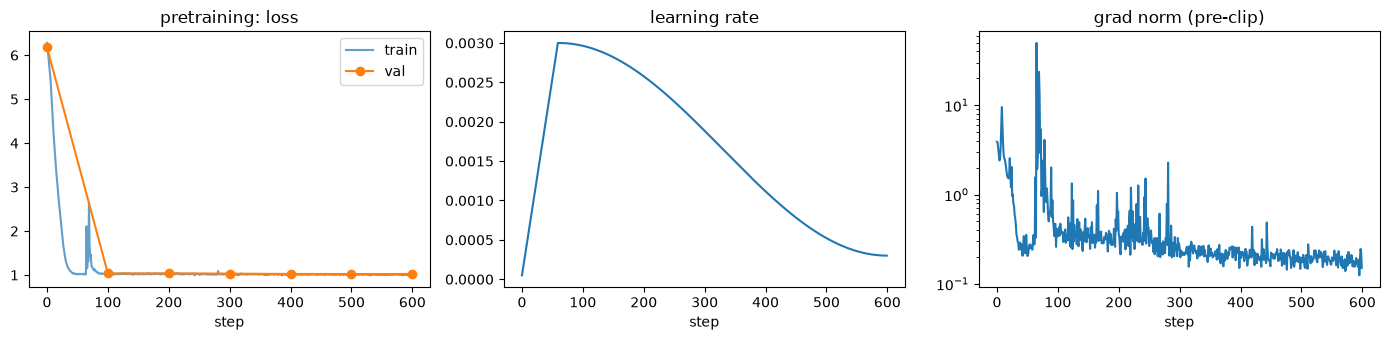

In [4]:
from llm_edu_suite.training import TrainConfig, train_lm, plot_training

tcfg = TrainConfig(steps=600, batch_size=32, block_size=128, max_lr=3e-3, warmup=60, schedule="cosine",
                   weight_decay=0.1, grad_clip=1.0, eval_every=100, checkpoint_path=os.path.join(tempfile.gettempdir(), "pretrain_ckpt.pt"))
res = train_lm(model, train_data, val_data, tcfg, device)
plot_training(res, "pretraining"); import matplotlib.pyplot as plt; plt.show()

**Reading the dashboard**: loss should fall monotonically (noisy per step is fine); grad norm should stay O(1) — a spike with a loss jump is instability (lower LR, longer warmup, add QK-norm: `ModelConfig(qk_norm=True)`); the LR curve confirms warmup/decay happened as intended.

## 4. Generate

A pre-trained model is a *distribution*, and generation means sampling from it one token at a time, feeding each choice back as input. The three settings below (greedy, temperature with top-k, temperature with top-p) are the standard decoding strategies; notebook 10 explains them in detail and shows how they reshape the distribution. Note what the model has *not* learned: it continues text in the style of its corpus, but it has no notion of following instructions. That behaviour comes from the post-training of notebooks 13 and 14.

In [5]:
prompt = torch.tensor([tok.encode("The model")], device=device)
for name, kw in {"greedy": dict(temperature=0.0), "T=0.8 top-k 40": dict(temperature=0.8, top_k=40), "T=1.0 top-p 0.9": dict(temperature=1.0, top_p=0.9)}.items():
    out = model.generate(prompt, 40, eos_id=tok.eos_id, **kw)
    print(f"{name:16s}| {tok.decode(out[0].tolist())!r}")

greedy          | 'The model predicts the input text in parallel. The attention layer encodes the input text in parallel. The attention layer encodes the input text in one forward pass. The attention layer encodes the validation set in one forward pass. The attention layer'


T=0.8 top-k 40  | 'The model predicts past keys and values quite efficiently. The attention layer learns the input text quite efficiently. The embedding table compresses query and key in parallel. The model stores query and key at inference time. The optimizer normalizes each vector step'


T=1.0 top-p 0.9 | 'The model selects past keys and values in parallel. The attention layer learns each vector at inference time. The embedding table normalizes the next token at inference time. The embedding table encodes the input text with little memory. The optimizer predicts every'


## 5. Evaluation

1. **Perplexity** on held-out text — the primary pretraining metric.
2. **How good is "good"? The irreducible loss.** Our corpus is generated by a known process: each sentence picks a subject, verb, object and tail uniformly from 10 options each, so it carries exactly $4\ln 10 = 9.21$ nats of information. Divided by the number of tokens per sentence, that is the **lowest loss any model can reach** (the $E$ term of the Chinchilla scaling law $L(N,D) = E + A/N^\alpha + B/D^\beta$). Real text has an unknown, much higher floor — that is why real LMs keep improving with scale while ours saturates.
3. **Schedule ablation** — cosine vs WSD at equal steps.
4. **Scaling sanity** — a bigger model should learn faster / reach lower loss at the same steps if data is not the bottleneck.

Because our model already sits at the floor after ~100 steps, comparing *final* numbers would show nothing; we compare **learning curves at a short budget** instead, where the differences live.

**Reading the scaling law in this light.** In $L(N,D) = E + A/N^\alpha + B/D^\beta$, our setup makes the last two terms vanish quickly: the corpus is simple enough that even the small model has enough capacity ($A/N^\alpha$ small), and the generating process is so regular that a few hundred steps of data pin it down ($B/D^\beta$ small). What remains is $E$. Real language is the opposite case: its $E$ is unknown and the other two terms stay large for very large $N$ and $D$, so each 10x in compute keeps buying a visible improvement. If you ever see a real pretraining curve flatten early, suspect the data (too small, too repetitive, or contaminated) or the optimizer before you conclude that you hit the floor.

**Why compare at a fixed number of steps?** A scaling comparison is only meaningful when everything except the variable under study is held fixed: same data order (same seed), same tokens seen, same schedule shape. A bigger model costs more FLOPs per step, so "same steps" is not "same compute"; in a compute-matched comparison you would give the smaller model proportionally more steps.

In [6]:
from llm_edu_suite.evaluation import perplexity
n_sentences = 20_000
floor_loss = 4 * math.log(10) * n_sentences / len(ids)          # true information content, in nats per token
val_ppl = perplexity(model, val_data, block_size=128, n_batches=20, device=device)
print(f"tokens per sentence      : {len(ids) / n_sentences:.2f}")
print(f"irreducible loss (floor) : {floor_loss:.3f} nats/token  -> perplexity floor {math.exp(floor_loss):.2f}")
print(f"our model                : val perplexity {val_ppl:.2f}  ({100 * (math.log(val_ppl) / floor_loss - 1):+.1f}% above the floor in loss)")

tokens per sentence      : 9.11
irreducible loss (floor) : 1.011 nats/token  -> perplexity floor 2.75
our model                : val perplexity 2.79  (+1.5% above the floor in loss)


schedule cosine: val loss @50 1.054 | final 1.024


schedule wsd   : val loss @50 1.053 | final 1.027


size 125.31K: val loss @50 1.259 | final 1.037


size   1.67M: val loss @50 1.054 | final 1.024


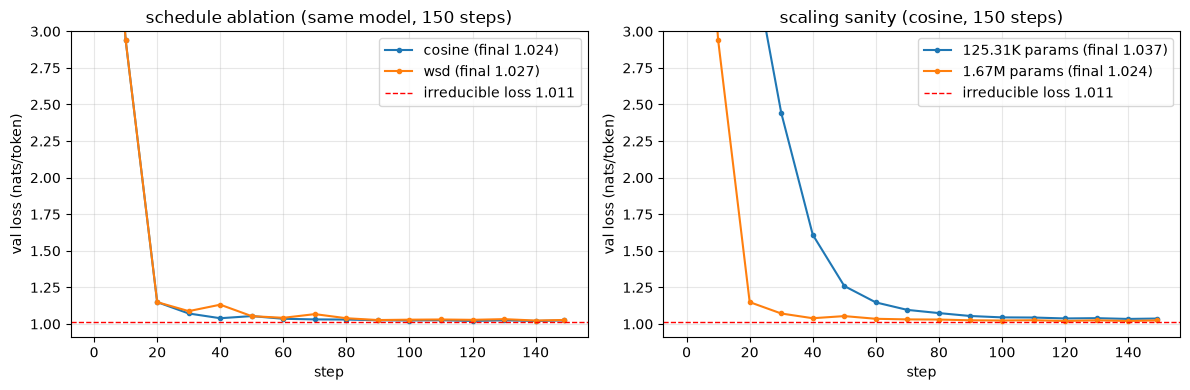

In [7]:
def curve(cfg_, sched="cosine", steps=150):
    seed_everything(0)
    m = TransformerLM(cfg_)
    r = train_lm(m, train_data, val_data, TrainConfig(steps=steps, batch_size=32, block_size=128, max_lr=3e-3, warmup=15,
                                                      schedule=sched, eval_every=10, eval_batches=5, log=False), device)
    return m, r

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for sched in ("cosine", "wsd"):
    m, r = curve(cfg, sched)
    s_, v_ = zip(*r.val_losses); ax[0].plot(s_, v_, "o-", ms=3, label=f"{sched} (final {v_[-1]:.3f})")
    print(f"schedule {sched:6s}: val loss @50 {dict(r.val_losses)[50]:.3f} | final {v_[-1]:.3f}")
ax[0].set_title("schedule ablation (same model, 150 steps)")

for d_model, n_layers in [(64, 2), (192, 4)]:
    c = ModelConfig(vocab_size=tok.vocab_size, max_seq_len=256, d_model=d_model, n_layers=n_layers, n_heads=4 if d_model == 64 else 6, n_kv_heads=2)
    m, r = curve(c)
    s_, v_ = zip(*r.val_losses); ax[1].plot(s_, v_, "o-", ms=3, label=f"{human(m.num_params())} params (final {v_[-1]:.3f})")
    print(f"size {human(m.num_params()):>7}: val loss @50 {dict(r.val_losses)[50]:.3f} | final {v_[-1]:.3f}")
ax[1].set_title("scaling sanity (cosine, 150 steps)")
for a in ax:
    a.axhline(floor_loss, color="red", ls="--", lw=1, label=f"irreducible loss {floor_loss:.3f}")
    a.set_ylim(floor_loss - 0.1, 3.0); a.set_xlabel("step"); a.set_ylabel("val loss (nats/token)"); a.grid(alpha=.3); a.legend()
plt.tight_layout(); plt.show()

**What to read from these plots**
- Every curve converges to the red line: once a model reaches the irreducible loss, more parameters or a better schedule cannot help — the only way to go lower is *more information in the data*.
- The bigger model gets there in fewer steps (higher sample efficiency) — that is the scaling behaviour you see in real pretraining, where the floor is far away.
- Cosine and WSD end up practically identical here. WSD keeps the LR high for longer and decays only at the end; its practical advantage is operational: you can extend a run from the stable phase (or branch several decays from one checkpoint) without restarting the schedule — which is why several recent open models use it.

## 6. Save / load
The checkpoint stores the config and weights; `TransformerLM.load` rebuilds the exact model. The tokenizer is saved alongside — a model is useless without *its* tokenizer.

For *inference* weights plus config plus tokenizer are enough. To *resume training* exactly you also need the optimizer state (Adam's $m$ and $v$, which are twice the size of the weights in fp32), the step counter (the schedule depends on it), the RNG states and the position in the data stream. Large runs checkpoint all of this regularly, because over weeks on thousands of GPUs hardware failures are routine rather than exceptional.

In [8]:
model.save(os.path.join(tempfile.gettempdir(), "mini_lm.pt")); tok.save(os.path.join(tempfile.gettempdir(), "mini_lm_tokenizer.json"))
m2 = TransformerLM.load(os.path.join(tempfile.gettempdir(), "mini_lm.pt")).to(device); t2 = ByteBPETokenizer.load(os.path.join(tempfile.gettempdir(), "mini_lm_tokenizer.json"))
with torch.no_grad():
    a, _ = model(x); b, _ = m2(x)
print("reloaded model identical:", torch.allclose(a, b, atol=1e-6))

reloaded model identical: True


## Results

| question | measured | lesson |
|---|---|---|
| tokenization | 1,121,799 characters → 182,129 tokens (6.16 characters per token) with a 1,024-token BPE | a domain tokenizer compresses its own text well |
| sanity checks | 1.67M parameters; initial loss 6.295 vs ln V = 6.240; no future leak | check both before spending compute |
| training | 600 steps in 13.1 s: val loss 6.180 → 1.023; grad norm 3.90 → 0.15 | a stable run: loss falls, grad norm stays O(1) |
| how close to the best possible? | floor 1.011 nats/token (perplexity 2.75); model perplexity 2.79, +1.5 % in loss | this corpus is learned; more steps cannot help |
| cosine vs WSD (150 steps) | final val loss 1.024 vs 1.027 | same result; WSD's advantage is operational |
| bigger model (150 steps) | 125.31K params: 1.259 at step 50, 1.037 final; 1.67M: 1.054 and 1.024 | larger models learn faster per step |
| save and reload | reloaded model identical | inference needs config + weights + tokenizer |

## In production

**From here to a real LLM.**
- The same loop wrapped in FSDP or DDP (`torchtitan` is the reference), a memory-mapped token file instead of a tensor in RAM, bf16 + `torch.compile`, and checkpoints every few hundred steps that also save optimizer state, step and data position.
- Far more data than the compute-optimal ~20 tokens per parameter of Chinchilla: modern small models are over-trained on 100–2000 tokens per parameter, because a smaller model is cheaper to serve.
- Data work dominates: deduplication, quality filtering and mixing (FineWeb-style pipelines, notebook 07). Read the Llama 3 and DeepSeek-V3 reports for the recipes.

**Who does this today.** Full pre-training is done by a few labs and well-funded groups. Most teams do continued pre-training on domain text, or fine-tuning (notebooks 13–14), starting from open weights. Small from-scratch runs are still useful for research, ablations and tokenizer or architecture tests.

**Tools.** `torchtitan`, Megatron-LM, DeepSpeed, Hugging Face `nanotron` and `datatrove`; Weights & Biases or MLflow for the training dashboard.

**Failure modes.**
- Loss spikes from too high a learning rate or too short a warmup (QK-norm and gradient clipping help).
- Validation contaminated by near-duplicates of training documents.
- Benchmark contamination: test sets that leaked into the crawl.
- Hardware failures without recent, complete checkpoints.
- A flat curve blamed on "the floor" when the data is too small or repetitive.

**Next:** `09_systems_memory_and_parallelism.ipynb` (what training costs in memory, kernels and GPUs, and how it scales), then `10_inference_serving.ipynb`.